This notebook contains data exploation of merged data (GEE + GSO).

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/vietnam_rice_dataset.csv")

In [7]:
df.head()

,ADM0_CODE,ADM0_NAME,ADM1_CODE,ADM1_NAME,DISP_AREA,EXP1_YEAR,STATUS,STR1_YEAR,Shape_Area,Shape_Leng,...,precip_total_mm,temp_mean_c,composite_key,macro_region,planted_area_ha,production_tons,yield_ton_ha,province_name,year,season
0,264,Viet Nam,3362,Long An,NO,3000,Member State,1000,0.369895,4.568725,...,979.289736,26.476687,long_an_2010_thudong,Mekong River Delta,12.3,39.4,3.20,Long An,2010,winter
1,264,Viet Nam,3362,Long An,NO,3000,Member State,1000,0.369895,4.568725,...,387.968208,26.441488,long_an_2011_dongxuan,Mekong River Delta,227.2,1486.0,5.85,Long An,2011,spring
2,264,Viet Nam,3362,Long An,NO,3000,Member State,1000,0.369895,4.568725,...,906.836826,27.254839,long_an_2011_hethu,Mekong River Delta,220.2,1031.5,4.68,Long An,2011,autumn
3,264,Viet Nam,3362,Long An,NO,3000,Member State,1000,0.369895,4.568725,...,844.459161,26.545149,long_an_2011_thudong,Mekong River Delta,10.0,33.2,3.32,Long An,2011,winter
4,264,Viet Nam,3362,Long An,NO,3000,Member State,1000,0.369895,4.568725,...,345.174066,27.167817,long_an_2012_dongxuan,Mekong River Delta,227.2,1596.5,6.09,Long An,2012,spring


In [4]:
df.columns

Index(['ADM0_CODE', 'ADM0_NAME', 'ADM1_CODE', 'ADM1_NAME', 'DISP_AREA',
       'EXP1_YEAR', 'STATUS', 'STR1_YEAR', 'Shape_Area', 'Shape_Leng',
       'VH_VV_ratio_mean', 'VH_max', 'VH_mean', 'VH_min', 'VH_range', 'VV_max',
       'VV_mean', 'VV_min', 'VV_range', 'precip_total_mm', 'temp_mean_c',
       'composite_key', 'macro_region', 'planted_area_ha', 'production_tons',
       'yield_ton_ha', 'province_name', 'year', 'season'],
      dtype='str')

In [9]:
cols_to_drop = [
    'ADM0_CODE', 'ADM0_NAME', 'ADM1_CODE', 'ADM1_NAME', 
    'DISP_AREA', 'EXP1_YEAR', 'STATUS', 'STR1_YEAR', 
    'Shape_Area', 'Shape_Leng', 'composite_key'
]

cleaned_df = df.drop(columns=cols_to_drop, errors='ignore')

print("Remaining columns:", cleaned_df.columns.tolist())

Remaining columns: ['VH_VV_ratio_mean', 'VH_max', 'VH_mean', 'VH_min', 'VH_range', 'VV_max', 'VV_mean', 'VV_min', 'VV_range', 'precip_total_mm', 'temp_mean_c', 'macro_region', 'planted_area_ha', 'production_tons', 'yield_ton_ha', 'province_name', 'year', 'season']


In [10]:
# Check data types and non-null counts
display(cleaned_df.info())

# Get statistical summary for numerical columns
display(cleaned_df.describe().T[['mean', 'std', 'min', '50%', 'max']])

# Check missing values per column
missing_counts = cleaned_df.isnull().sum()
print("Missing values per column:\n", missing_counts[missing_counts > 0])

<class 'pandas.DataFrame'>
RangeIndex: 2886 entries, 0 to 2885
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   VH_VV_ratio_mean  1517 non-null   float64
 1   VH_max            1517 non-null   float64
 2   VH_mean           1517 non-null   float64
 3   VH_min            1517 non-null   float64
 4   VH_range          1517 non-null   float64
 5   VV_max            1517 non-null   float64
 6   VV_mean           1517 non-null   float64
 7   VV_min            1517 non-null   float64
 8   VV_range          1517 non-null   float64
 9   precip_total_mm   2886 non-null   float64
 10  temp_mean_c       2886 non-null   float64
 11  macro_region      2886 non-null   str    
 12  planted_area_ha   2886 non-null   float64
 13  production_tons   2886 non-null   float64
 14  yield_ton_ha      2886 non-null   float64
 15  province_name     2886 non-null   str    
 16  year              2886 non-null   int64  
 17  season

None

,mean,std,min,50%,max
VH_VV_ratio_mean,-7.000595,0.538968,-8.787300,-6.954446,-5.631870
VH_max,-13.779410,0.776952,-18.496753,-13.662959,-11.928210
VH_mean,-16.334244,1.235594,-21.650438,-16.317351,-13.275973
VH_min,-19.401893,2.442757,-41.514284,-19.252719,-13.318978
VH_range,5.622483,2.287158,0.002667,5.483110,28.353643
VV_max,-6.790921,0.651348,-11.750348,-6.707382,-5.280168
VV_mean,-9.333947,0.984920,-14.534862,-9.216322,-6.590877
VV_min,-12.298018,2.134106,-38.093516,-12.043070,-7.040566
VV_range,5.507096,2.162039,0.002743,5.191573,31.528565
precip_total_mm,597.914635,326.652142,32.765579,580.461102,2283.360682


Missing values per column:
 VH_VV_ratio_mean    1369
VH_max              1369
VH_mean             1369
VH_min              1369
VH_range            1369
VV_max              1369
VV_mean             1369
VV_min              1369
VV_range            1369
dtype: int64


In [17]:
print(cleaned_df[cleaned_df['VH_mean'].isna()]['year'].value_counts().sort_index())

year
2005    138
2006    138
2007    137
2008    137
2009    137
2010    137
2011    137
2012    137
2013    137
2014    107
2021      1
2022      2
2023      8
2024     14
2025      2
Name: count, dtype: int64


In [19]:
cleaned_df = cleaned_df[(cleaned_df['year'] >= 2015)]

## EDA

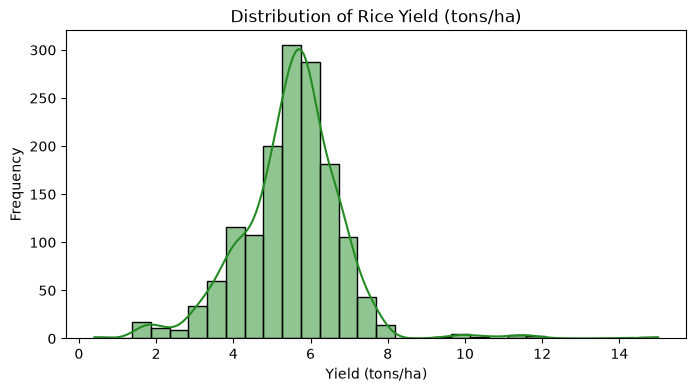

In [20]:
plt.figure(figsize=(8, 4))
sns.histplot(cleaned_df['yield_ton_ha'], kde=True, bins=30, color='forestgreen')
plt.title('Distribution of Rice Yield (tons/ha)')
plt.xlabel('Yield (tons/ha)')
plt.ylabel('Frequency')
plt.show()

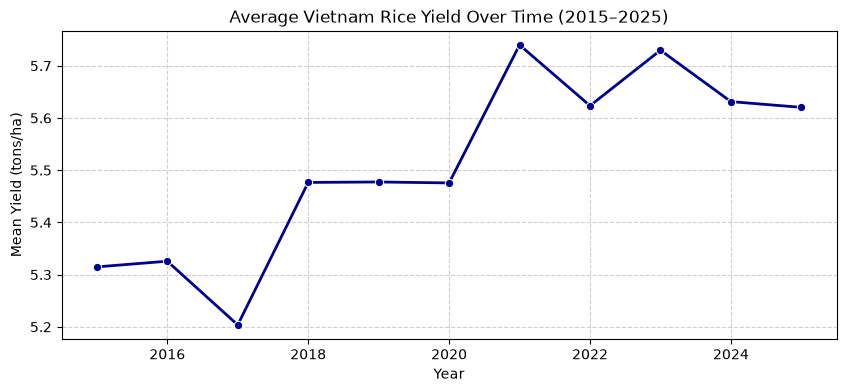

In [22]:
plt.figure(figsize=(10, 4))
yearly_yield = cleaned_df.groupby('year')['yield_ton_ha'].mean().resetfn = cleaned_df.groupby('year')['yield_ton_ha'].mean().reset_index()

sns.lineplot(data=yearly_yield, x='year', y='yield_ton_ha', marker='o', color='darkblue', linewidth=2)
plt.title('Average Vietnam Rice Yield Over Time (2015–2025)')
plt.xlabel('Year')
plt.ylabel('Mean Yield (tons/ha)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

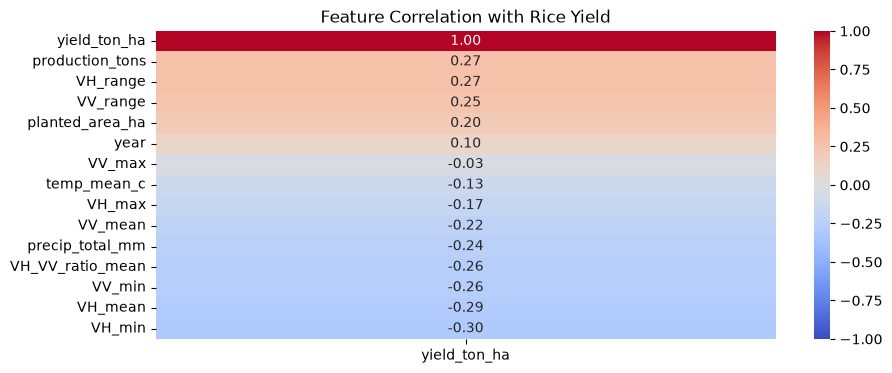

In [23]:
plt.figure(figsize=(10, 4))
# Select numeric columns
numeric_cols = cleaned_df.select_dtypes(include=['number']).columns
correlation_matrix = cleaned_df[numeric_cols].corr()

# Plot heatmap focused on correlations with yield
sns.heatmap(
    correlation_matrix[['yield_ton_ha']].sort_values(by='yield_ton_ha', ascending=False), 
    annot=True, 
    cmap='coolwarm', 
    vmin=-1, 
    vmax=1, 
    fmt='.2f'
)
plt.title('Feature Correlation with Rice Yield')
plt.show()

In [24]:
import pyarrow

# Bypass PyArrow registration quirk and save to Parquet
try:
    _period_type = pyarrow.lib.ExtensionType("pandas.period")
except Exception:
    pass

OUTPUT_PARQUET = Path("../data/vietnam_rice_dataset_2015_2025.parquet")
OUTPUT_PARQUET.parent.mkdir(parents=True, exist_ok=True)
cleaned_df.to_parquet(OUTPUT_PARQUET, index=False, engine='pyarrow')

print(f"Saved to: {OUTPUT_PARQUET}")

Saved to: ..\data\vietnam_rice_dataset_2015_2025.parquet
